# Stage 8: Test Error Analysis

Analyze saved Stage 7 predictions only. The validation-selected model remains fixed; test results are descriptive and do not change selection. Rainfall-category comparisons describe this held-out sample and are not causal estimates.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().resolve()
if project_root.name == 'Notebooks':
    project_root = project_root.parent
data_dir = project_root / 'DataProcessed'
predictions = pd.read_csv(data_dir / 'advanced_forecasting_predictions.csv', parse_dates=['time'])
metrics = pd.read_csv(data_dir / 'advanced_forecasting_metrics.csv')
features = pd.read_csv(data_dir / 'metro_weather_features_final.csv', parse_dates=['time'])
test = pd.read_csv(data_dir / 'metro_weather_test_prepared.csv', parse_dates=['time'])
validation_metrics = metrics.loc[metrics.split.eq('validation')].sort_values(['MAE', 'RMSE'])
selected_model = validation_metrics.iloc[0].model
assert selected_model == 'RandomForest_B_plus_weather'
assert not test.duplicated(['time', 'direction']).any()
assert not features.duplicated(['time', 'direction']).any()
assert test.groupby('time').direction.nunique().eq(2).all()
assert test[['time', 'direction']].equals(test[['time', 'direction']].sort_values(['time', 'direction']).reset_index(drop=True))
assert test.time.min() == pd.Timestamp('2025-02-02 00:00:00') and test.time.max() == pd.Timestamp('2025-02-28 23:00:00')
group_fields = features[['time', 'direction', 'hour', 'day_of_week', 'is_weekend', 'rainfall_intensity']]
test_groups = test.merge(group_fields, on=['time', 'direction'], how='left', validate='one_to_one')
assert len(test_groups) == len(test) and test_groups[['hour', 'day_of_week', 'is_weekend', 'rainfall_intensity']].notna().all().all()
test_predictions = predictions.loc[predictions.split.eq('test')].merge(
    test_groups[['time', 'direction', 'hour', 'day_of_week', 'is_weekend', 'rainfall_intensity']],
    on=['time', 'direction'], how='left', validate='many_to_one'
)
test_predictions = test_predictions.sort_values(['model', 'time', 'direction']).reset_index(drop=True)
expected_actual = test.set_index(['time', 'direction']).ridership_count
for model, frame in test_predictions.groupby('model'):
    assert len(frame) == len(test)
    assert not frame.duplicated(['time', 'direction']).any()
    assert frame.prediction.notna().all() and frame[['hour', 'day_of_week', 'is_weekend', 'rainfall_intensity']].notna().all().all()
    indexed = frame.set_index(['time', 'direction'])
    assert indexed.index.equals(expected_actual.index.sort_values())
    assert np.array_equal(indexed.actual.to_numpy(), expected_actual.reindex(indexed.index).to_numpy())
print('Validation-selected model:', selected_model)
print('Test rows:', len(test), '| directions:', test.direction.value_counts().to_dict(), '| model count:', test_predictions.model.nunique())
print('Rain intensity counts:', test_groups.rainfall_intensity.value_counts().reindex(['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain'], fill_value=0).to_dict())

Validation-selected model: RandomForest_B_plus_weather
Test rows: 810 | directions: {'Entry': 405, 'Exit': 405} | model count: 8
Rain intensity counts: {'No Rain': 778, 'Light Rain': 30, 'Moderate Rain': 2, 'Heavy Rain': 0}


## Grouped Errors

Tables report sample count, MAE, and RMSE for the validation-selected model, the paired Random Forest without weather, and seasonal naive. Empty groups are retained with missing metrics; groups under 10 rows are marked sparse.

In [3]:
models_to_report = [selected_model, 'RandomForest_A_temporal_history', 'SeasonalNaive_24h']
assert set(models_to_report).issubset(set(test_predictions.model))
dimension_values = {
    'direction': ['Entry', 'Exit'],
    'hour': list(range(24)),
    'day_type': ['Weekday', 'Weekend'],
    'rainfall_intensity': ['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain']
}
test_predictions['day_type'] = np.where(test_predictions.is_weekend.eq(1), 'Weekend', 'Weekday')
breakdown_rows = []
for model in models_to_report:
    model_rows = test_predictions.loc[test_predictions.model.eq(model)]
    for dimension, categories in dimension_values.items():
        for category in categories:
            group = model_rows.loc[model_rows[dimension].eq(category)]
            count = len(group)
            if count:
                error = group.prediction.to_numpy() - group.actual.to_numpy()
                mae = float(np.mean(np.abs(error)))
                rmse = float(np.sqrt(np.mean(error ** 2)))
            else:
                mae, rmse = np.nan, np.nan
            status = 'empty' if count == 0 else ('sparse (n<10)' if count < 10 else 'ok')
            breakdown_rows.append({'model': model, 'dimension': dimension, 'group': category, 'n': count, 'MAE': mae, 'RMSE': rmse, 'sample_note': status})
error_breakdown = pd.DataFrame(breakdown_rows)
for model in models_to_report:
    for dimension in dimension_values:
        assert error_breakdown.loc[error_breakdown.model.eq(model) & error_breakdown.dimension.eq(dimension), 'n'].sum() == len(test)

rf_a = test_predictions.loc[test_predictions.model.eq('RandomForest_A_temporal_history')].set_index(['time', 'direction']).sort_index()
rf_b = test_predictions.loc[test_predictions.model.eq('RandomForest_B_plus_weather')].set_index(['time', 'direction']).sort_index()
assert rf_a.index.equals(rf_b.index) and np.array_equal(rf_a.actual.to_numpy(), rf_b.actual.to_numpy())
weather_rows = []
for category in ['All test rows', *dimension_values['rainfall_intensity']]:
    mask = np.ones(len(rf_a), dtype=bool) if category == 'All test rows' else rf_a.rainfall_intensity.eq(category).to_numpy()
    count = int(mask.sum())
    if count:
        actual = rf_a.actual.to_numpy()[mask]
        error_a = rf_a.prediction.to_numpy()[mask] - actual
        error_b = rf_b.prediction.to_numpy()[mask] - actual
        mae_a, mae_b = np.mean(np.abs(error_a)), np.mean(np.abs(error_b))
        rmse_a, rmse_b = np.sqrt(np.mean(error_a**2)), np.sqrt(np.mean(error_b**2))
        mae_change, rmse_change = mae_b-mae_a, rmse_b-rmse_a
    else:
        mae_a = mae_b = rmse_a = rmse_b = mae_change = rmse_change = np.nan
    weather_rows.append({'rainfall_group': category, 'n': count, 'MAE_no_weather': mae_a, 'MAE_with_weather': mae_b, 'MAE_change_B_minus_A': mae_change, 'RMSE_no_weather': rmse_a, 'RMSE_with_weather': rmse_b, 'RMSE_change_B_minus_A': rmse_change, 'sample_note': 'empty' if count == 0 else ('sparse (n<10)' if count < 10 else 'ok')})
weather_comparison = pd.DataFrame(weather_rows)
weather_comparison['MAE_improved'] = weather_comparison['MAE_change_B_minus_A'].lt(0).mask(weather_comparison.n.eq(0), pd.NA).astype('boolean')
error_path = data_dir / 'stage8_test_error_breakdown.csv'
weather_path = data_dir / 'stage8_weather_value_test.csv'
error_breakdown.to_csv(error_path, index=False)
weather_comparison.to_csv(weather_path, index=False)
print('Grouped test errors:')
display(error_breakdown)
print('Paired RF weather comparison; negative B-A is lower error:')
display(weather_comparison)
print('Saved:', error_path, weather_path)

Grouped test errors:


,model,dimension,group,n,MAE,RMSE,sample_note
0,RandomForest_B_plus_weather,direction,Entry,405,4483.144917,7065.378355,ok
1,RandomForest_B_plus_weather,direction,Exit,405,5106.670190,8479.313677,ok
2,RandomForest_B_plus_weather,hour,0,54,261.057999,428.330424,ok
3,RandomForest_B_plus_weather,hour,1,0,NaN,NaN,empty
4,RandomForest_B_plus_weather,hour,2,0,NaN,NaN,empty
...,...,...,...,...,...,...,...
91,SeasonalNaive_24h,day_type,Weekend,210,21414.585714,33365.581081,ok
92,SeasonalNaive_24h,rainfall_intensity,No Rain,778,23100.651671,43224.897867,ok
93,SeasonalNaive_24h,rainfall_intensity,Light Rain,30,9566.000000,26173.560359,ok
94,SeasonalNaive_24h,rainfall_intensity,Moderate Rain,2,17571.000000,17974.044231,sparse (n<10)


Paired RF weather comparison; negative B-A is lower error:


,rainfall_group,n,MAE_no_weather,MAE_with_weather,MAE_change_B_minus_A,RMSE_no_weather,RMSE_with_weather,RMSE_change_B_minus_A,sample_note,MAE_improved
0,All test rows,810,4449.933389,4794.907553,344.974165,7127.348612,7804.432450,677.083837,ok,False
1,No Rain,778,4451.842475,4815.748300,363.905825,7095.248498,7818.106928,722.858430,ok,False
2,Light Rain,30,4539.425845,4309.062138,-230.363707,8098.466523,7631.998601,-466.467922,ok,True
3,Moderate Rain,2,2364.911952,3975.538253,1610.626300,2570.010634,4211.118277,1641.107644,sparse (n<10),False
4,Heavy Rain,0,NaN,NaN,NaN,NaN,NaN,NaN,empty,<NA>


Saved: /Users/shivaya/Desktop/Desktop - Utkarsh’s MacBook Pro/Research/DelhiMetroResearch/DataProcessed/stage8_test_error_breakdown.csv /Users/shivaya/Desktop/Desktop - Utkarsh’s MacBook Pro/Research/DelhiMetroResearch/DataProcessed/stage8_weather_value_test.csv


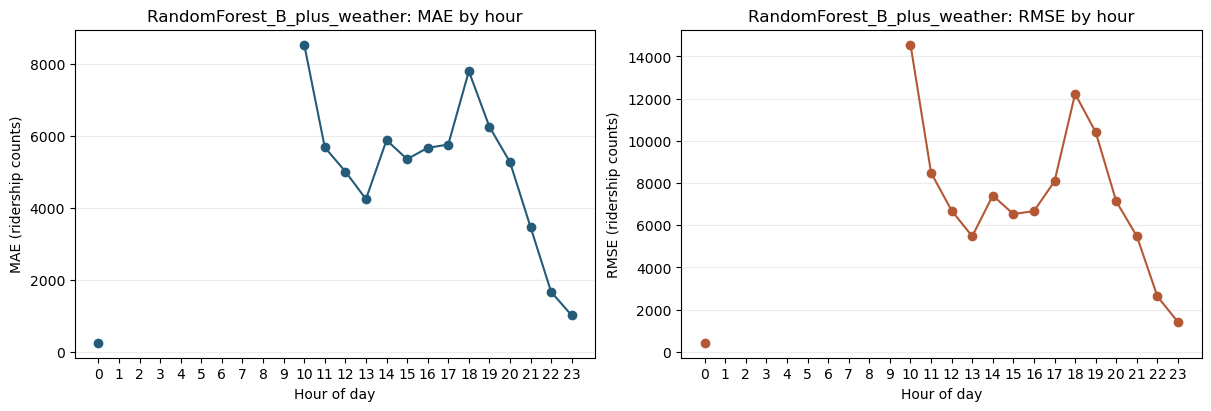

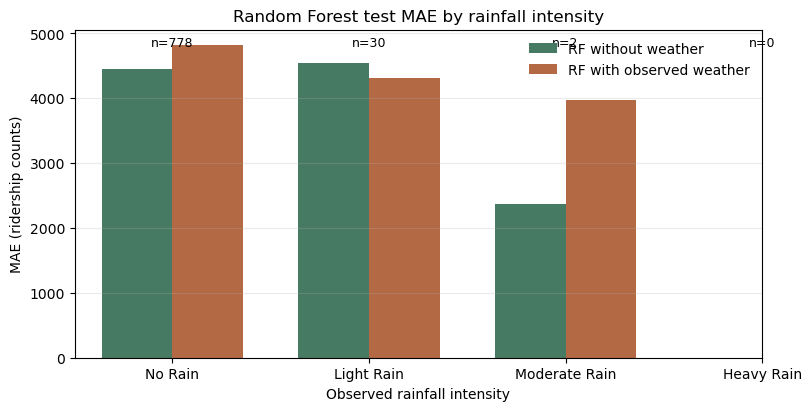

Saved plots: /Users/shivaya/Desktop/Desktop - Utkarsh’s MacBook Pro/Research/DelhiMetroResearch/DataProcessed/stage8_selected_model_hourly_errors.png /Users/shivaya/Desktop/Desktop - Utkarsh’s MacBook Pro/Research/DelhiMetroResearch/DataProcessed/stage8_rf_weather_rainfall_errors.png


In [4]:
selected_test = test_predictions.loc[test_predictions.model.eq(selected_model)]
selected_groups = error_breakdown.loc[error_breakdown.model.eq(selected_model)]
hourly = selected_groups.loc[selected_groups.dimension.eq('hour')].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(hourly.group, hourly.MAE, marker='o', color='#245b78')
axes[0].set(title=f'{selected_model}: MAE by hour', xlabel='Hour of day', ylabel='MAE (ridership counts)', xticks=range(24))
axes[0].grid(axis='y', alpha=0.25)
axes[1].plot(hourly.group, hourly.RMSE, marker='o', color='#b45735')
axes[1].set(title=f'{selected_model}: RMSE by hour', xlabel='Hour of day', ylabel='RMSE (ridership counts)', xticks=range(24))
axes[1].grid(axis='y', alpha=0.25)
hourly_plot_path = data_dir / 'stage8_selected_model_hourly_errors.png'
fig.savefig(hourly_plot_path, dpi=160)
plt.show()

categories = ['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain']
weather_plot = weather_comparison.set_index('rainfall_group').reindex(categories)
positions = np.arange(len(categories))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.bar(positions-width/2, weather_plot.MAE_no_weather, width, label='RF without weather', color='#477a63')
ax.bar(positions+width/2, weather_plot.MAE_with_weather, width, label='RF with observed weather', color='#b36a44')
for index, count in enumerate(weather_plot.n.fillna(0).astype(int)):
    ax.text(index, 0.98, f'n={count}', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=9)
ax.set(title='Random Forest test MAE by rainfall intensity', xlabel='Observed rainfall intensity', ylabel='MAE (ridership counts)', xticks=positions, xticklabels=categories)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
rain_plot_path = data_dir / 'stage8_rf_weather_rainfall_errors.png'
fig.savefig(rain_plot_path, dpi=160)
plt.show()
print('Saved plots:', hourly_plot_path, rain_plot_path)

In [6]:
overall = weather_comparison.iloc[0]
selected_rows = test_predictions.loc[test_predictions.model.eq(selected_model)]
selected_error = selected_rows.prediction.to_numpy() - selected_rows.actual.to_numpy()
selected_mae = float(np.mean(np.abs(selected_error)))
selected_rmse = float(np.sqrt(np.mean(selected_error ** 2)))
print(f"Validation-selected model: {selected_model}. Test MAE/RMSE: {selected_mae:.1f}/{selected_rmse:.1f}.")
print(f"RF weather comparison, all {int(overall.n)} paired rows: MAE {overall.MAE_no_weather:.1f} to {overall.MAE_with_weather:.1f} ({overall.MAE_change_B_minus_A:+.1f}); RMSE {overall.RMSE_no_weather:.1f} to {overall.RMSE_with_weather:.1f} ({overall.RMSE_change_B_minus_A:+.1f}).")
for _, row in weather_comparison.iloc[1:].iterrows():
    if row.n:
        print(f"{row.rainfall_group}: n={int(row.n)}, MAE {row.MAE_no_weather:.1f} -> {row.MAE_with_weather:.1f} ({row.MAE_change_B_minus_A:+.1f}), {row.sample_note}.")
    else:
        print(f"{row.rainfall_group}: n=0; no test estimate.")
print('No overall weather improvement is evident on this test set. The slight light-rain improvement (n=30) is descriptive; moderate rain has n=2 and heavy rain n=0, so rainfall-specific value is inconclusive.')
print('Weather columns use observed prediction-hour conditions; these are retrospective, not operational forecasts. No causal interpretation is warranted.')

Validation-selected model: RandomForest_B_plus_weather. Test MAE/RMSE: 4794.9/7804.4.
RF weather comparison, all 810 paired rows: MAE 4449.9 to 4794.9 (+345.0); RMSE 7127.3 to 7804.4 (+677.1).
No Rain: n=778, MAE 4451.8 -> 4815.7 (+363.9), ok.
Light Rain: n=30, MAE 4539.4 -> 4309.1 (-230.4), ok.
Moderate Rain: n=2, MAE 2364.9 -> 3975.5 (+1610.6), sparse (n<10).
Heavy Rain: n=0; no test estimate.
No overall weather improvement is evident on this test set. The slight light-rain improvement (n=30) is descriptive; moderate rain has n=2 and heavy rain n=0, so rainfall-specific value is inconclusive.
Weather columns use observed prediction-hour conditions; these are retrospective, not operational forecasts. No causal interpretation is warranted.


In [9]:
# Read back every saved result and independently reproduce each displayed group score.
saved_breakdown = pd.read_csv(error_path)
saved_weather = pd.read_csv(weather_path)
saved_stage7_metrics = pd.read_csv(data_dir / 'advanced_forecasting_metrics.csv')
saved_stage7_predictions = pd.read_csv(data_dir / 'advanced_forecasting_predictions.csv', parse_dates=['time'])
assert selected_model == saved_stage7_metrics.loc[saved_stage7_metrics.split.eq('validation')].sort_values(['MAE', 'RMSE']).iloc[0].model
assert len(saved_stage7_predictions.query("split == 'test' and model == @selected_model")) == len(test)
assert saved_weather.loc[saved_weather.rainfall_group.eq('All test rows'), 'n'].iloc[0] == len(test)
assert saved_weather.loc[saved_weather.rainfall_group.eq('Heavy Rain'), 'n'].iloc[0] == 0

for row in saved_breakdown.itertuples(index=False):
    group = test_predictions.loc[test_predictions.model.eq(row.model)]
    if row.dimension == 'day_type':
        group = group.loc[group.day_type.eq(row.group)]
    elif row.dimension == 'hour':
        group = group.loc[group.hour.eq(int(row.group))]
    else:
        group = group.loc[group[row.dimension].eq(row.group)]
    assert len(group) == row.n, (row.model, row.dimension, row.group, len(group), row.n)
    if row.n:
        error = group.prediction.to_numpy() - group.actual.to_numpy()
        assert np.isclose(np.mean(np.abs(error)), row.MAE)
        assert np.isclose(np.sqrt(np.mean(error ** 2)), row.RMSE)
    else:
        assert pd.isna(row.MAE) and pd.isna(row.RMSE)

saved_rf_a = saved_stage7_predictions.query("split == 'test' and model == 'RandomForest_A_temporal_history'").sort_values(['time', 'direction']).reset_index(drop=True)
saved_rf_b = saved_stage7_predictions.query("split == 'test' and model == 'RandomForest_B_plus_weather'").sort_values(['time', 'direction']).reset_index(drop=True)
assert saved_rf_a[['time', 'direction']].equals(saved_rf_b[['time', 'direction']])
assert np.array_equal(saved_rf_a.actual.to_numpy(), saved_rf_b.actual.to_numpy())
for path in [error_path, weather_path, hourly_plot_path, rain_plot_path]:
    assert path.exists() and path.stat().st_size > 0
for model in models_to_report:
    for dimension in ['hour', 'direction', 'day_type', 'rainfall_intensity']:
        count = error_breakdown.loc[error_breakdown.model.eq(model) & error_breakdown.dimension.eq(dimension), 'n'].sum()
        assert count == len(test), (model, dimension, count)
print(f'PASS: {len(saved_breakdown)} saved group rows independently reproduced; RF A/B use identical {len(saved_rf_a)} test keys; predictions/outputs align and both plots/files exist.')
print('No models were retrained; validation selection is unchanged.')

PASS: 96 saved group rows independently reproduced; RF A/B use identical 810 test keys; predictions/outputs align and both plots/files exist.
No models were retrained; validation selection is unchanged.


## Key Findings & Conclusions

- **Selected model:** `RandomForest_B_plus_weather` (validation-selected); test MAE/RMSE **4,794.9 / 7,804.4** across 810 rows.
- **By direction:** Entry n=405, MAE/RMSE **4,483.1 / 7,065.4**; Exit n=405, **5,106.7 / 8,479.3**. The prepared test sample covers hour 00 and 10–23; unsupported hours remain empty in the breakdown.
- **Weather comparison:** On identical RF test rows, adding observed weather worsened overall MAE by **345.0** and RMSE by **677.1**. MAE improved in light rain (n=30, -230.4), worsened for no rain (n=778, +363.9), and worsened for moderate rain (n=2, +1,610.6); heavy rain had no cases.
- **Conclusion and limits:** No overall forecasting value from the weather bundle is demonstrated here, and rainfall-specific value is inconclusive because rainy strata are sparse. Prediction-hour observed weather is retrospective, not operational; these descriptive group differences do not establish causality. Use archived weather forecasts and more rainy test cases for a stronger operational assessment.